## Demonstration of spectral analysis of CH-2 XSM data with pyxspec

##### Mithun N P S, PRL Ahmedabad 
##### Contact: xsmpoc@prl.res.in

This notebook demonstrates spectral fitting of Chandrayaan-2 XSM observations of a flare in PyXSPEC. Fitting with isothermal model *chisoth* (CHIANTI based) is shown. 

#### Pre-requisites


* Download the data from XSM data archive at https://pradan.issdc.gov.in/ch2/ and unzip the file in the present working directory. 

* Install XSMDAS: XSM data analysis software in your system along with CALDB (see Section 3 of user guide at https://www.prl.res.in/ch2xsm/static/ch2_xsm_data_analysis_guide.pdf).

* Install XSPEC which is part of heasoft which will also build the python binding pyxspec. See https://heasarc.gsfc.nasa.gov/docs/xanadu/xspec/python/html/buildinstall.html for instructions 

* Python packages astropy, matplotlib, numpy, corner (in addition to some standard packages) are required for some specific parts 

* Local model distribution of chisoth (https://github.com/xastprl/chspec) is required for fitting with that model.


In [1]:
# Imports

from xspec import *

from datetime import datetime
import os
import numpy as np
from astropy.io import fits
import corner
import matplotlib.pyplot as plt


Chisoth a local model that needs to be loaded in XSPEC (not available by default) before using.
The model is available at https://github.com/xastprl/chspec

In [2]:
# Load chisoth model 
basepathmod='/Users/mithun/work/chandrayaan/xsm/science/chspec'
AllModels.lmod('chspec',dirPath=basepathmod)

Model package chspec successfully loaded.


#### Generate spectrum using XSMDAS

We generate spectrum using **xsmgenspec** task. Note that this can be done in loop to generate spectra for different time bins etc. 

 After these two steps, proceed with this notebook. 

In [3]:
tref=datetime(2017,1,1)
tstart=(datetime(2021,9,8,17,21)-tref).total_seconds()
tstop=(datetime(2021,9,8,17,22)-tref).total_seconds()

l1dir='xsm/data/2021/09/08/raw/'
l2dir='xsm/data/2021/09/08/calibrated/'

base='ch2_xsm_20210908_v1'

l1file=l1dir+'/'+base+'_level1.fits'
hkfile=l1dir+'/'+base+'_level1.hk'
safile=l1dir+'/'+base+'_level1.sa'
gtifile=l2dir+'/'+base+'_level2.gti'

specbase='ch2_xsm_20210908_172100-172200'
specfile=specbase+'.pha'

genspec_command="xsmgenspec l1file="+l1file+" specfile="+specfile+" spectype='time-integrated'"+ \
" tstart="+str(tstart)+" tstop="+str(tstop)+" hkfile="+hkfile+" safile="+safile+" gtifile="+gtifile

s=os.system(genspec_command)


-------------------------------------------------------------------------
  XSMDAS: Data Analysis Software for Chandrayaan-II Solar X-ray Monitor  
                     XSMDAS Version: 2.0              
                     Module : XSMGENSPEC                        
-------------------------------------------------------------------------
------------------------------------------------------------------------
MESSAGE: Ebounds CALDB file used is: /Users/mithun/work/chandrayaan/xsm/pipeline/XSM/xsmdas/caldb/CH2xsmebounds20191214v01.fits
MESSAGE: Gain CALDB file used is: /Users/mithun/work/chandrayaan/xsm/pipeline/XSM/xsmdas/caldb/CH2xsmgain20210401v01.fits
MESSAGE: Deadtcor CALDB file used is: /Users/mithun/work/chandrayaan/xsm/pipeline/XSM/xsmdas/caldb/CH2xsmdeadtcor20251111v01.fits
MESSAGE: Abscoef CALDB file used is: /Users/mithun/work/chandrayaan/xsm/pipeline/XSM/xsmdas/caldb/CH2xsmabscoef20200410v01.fits
MESSAGE: Effareapar CALDB file used is: /Users/mithun/work/chandrayaan/xsm/pi

#### Load spectrum in XSPEC and plot

Spectrum is loaded in XSPEC and plotted using XSPEC's plotting options. It is also possible to use matplotlib or other python libraries to plot the spectrum. How to ignore certain energy ranges for further analysis is also shown.

In [4]:

# Clear any previously loaded data and models

AllData.clear()
AllModels.clear()

# Load spectrum (ARF, RMF, background etc will be loaded automatically if specified in spectrum header)
spec = Spectrum(specfile)


# Set plot device, x-axis to energy instead of channel, plot spectrum
Plot.device = '/xw'    
Plot.xAxis = 'keV'

Plot('ld')



1 spectrum  in use
 
Spectral Data File: ch2_xsm_20210908_172100-172200.pha  Spectrum 1
Net count rate (cts/s) for Spectrum:1  2.412e+03 +/- 1.674e+01
 Assigned to Data Group 1 and Plot Group 1
  Noticed Channels:  1-512
  Telescope: CH-2_ORBITER Instrument: CH2_XSM  Channel Type: PI
  Exposure Time: 59.28 sec
 Using fit statistic: chi
 Using Response (RMF) File            /Users/mithun/work/chandrayaan/xsm/pipeline/XSM/xsmdas/caldb/CH2xsmresponse20200423v01.rmf for Source 1
 Using Auxiliary Response (ARF) File  ch2_xsm_20210908_172100-172200.arf



In [5]:
spec.ignore("**-1.0 8.0-**")
Plot('ld')

    16 channels (1-16) ignored in spectrum #     1
   285 channels (228-512) ignored in spectrum #     1



It is possible to extend the spectral fitting to higher energies by rebinning the spectrum so that there are more counts in each channel. This can be done using the HEASOFT FTOOL task **grppha**. This is required if one uses chisquare statistics for fitting which assumes Gaussian errors on the counts in each channel. Another option is to use other statistics such as cstat which does not make such assumptions

#### Fitting spectrum with chisoth model

We will now fit the spectrum using chisoth model that is based on CHIANTI database (Mondal et al, 2021, ApJ) available in chspec package. 
Initially, we start with a single isothermal model and try fitting the spectrum with 'chisoth' model.

In [6]:
# Set chisoth as model and do fit, free abundances, fit again.


m1 = Model("chisoth")

Fit.perform()
Plot('ld','delc')



Model chisoth<1> Source No.: 1   Active/On
Model Model Component  Parameter  Unit     Value
 par  comp
   1    1   chisoth    logT       K        6.39000      +/-  0.0          
   2    1   chisoth    He                  10.9000      frozen
   3    1   chisoth    Li                  1.64000      frozen
   4    1   chisoth    Be                  1.94000      frozen
   5    1   chisoth    B                   3.09000      frozen
   6    1   chisoth    C                   8.59000      frozen
   7    1   chisoth    N                   8.00000      frozen
   8    1   chisoth    O                   8.89000      frozen
   9    1   chisoth    F                   4.56000      frozen
  10    1   chisoth    Ne                  8.08000      frozen
  11    1   chisoth    Na                  6.93000      frozen
  12    1   chisoth    Mg                  8.15000      frozen
  13    1   chisoth    Al                  7.04000      frozen
  14    1   chisoth    Si                  8.10000      frozen
  

To plot the spectrum and fit using matplotlib, a function is written as below and we plot the spectrum, best fit model, and residuals.

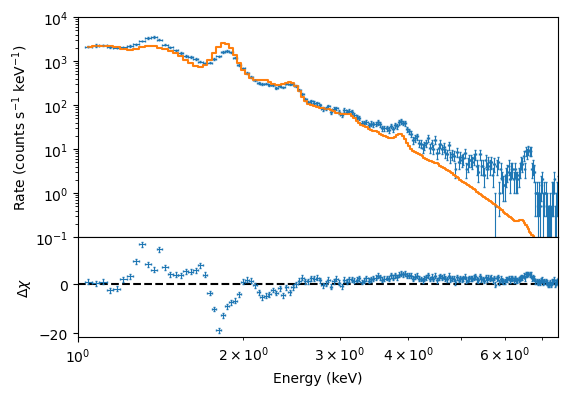

In [7]:

def doPlot():
    Plot('ld','delc')

    ene=Plot.x(plotGroup=1, plotWindow=1)
    eneErr=Plot.xErr(plotGroup=1, plotWindow=1)
    spec=Plot.y(plotGroup=1, plotWindow=1)
    specErr=Plot.yErr(plotGroup=1, plotWindow=1)
        
    fitmodel=Plot.model(plotGroup=1, plotWindow=1)
        
    delchi=Plot.y(plotGroup=1, plotWindow=2)
    delchiErr=Plot.yErr(plotGroup=1, plotWindow=2)

    fig0 = plt.figure(num=None, figsize=(6, 4), facecolor='w', edgecolor='k')
        
    ax0 = fig0.add_axes([0.15, 0.4, 0.8, 0.55])
    ax0.xaxis.set_visible(False)
    plt.errorbar(ene,spec,xerr=eneErr,yerr=specErr,fmt='.',ms=0.5,capsize=1.0,lw=0.8)
    plt.step(ene,fitmodel,where='mid')
    plt.yscale("log")
    plt.xscale("log")
    plt.xlim([1.0,7.5])
    plt.ylim([0.1,1e4])
    plt.ylabel('Rate (counts s$^{-1}$ keV$^{-1}$)')


    ax1 = fig0.add_axes([0.15, 0.15, 0.8, 0.25])
    plt.axhline(0,linestyle='dashed',color='black')
    plt.errorbar(ene,delchi,xerr=eneErr,yerr=delchiErr,fmt='.',ms=0.1,capsize=1.0,lw=0.8)
    plt.xscale("log")
    plt.xlim([1.0,7.5])         
    plt.ylabel('$\Delta \chi$')

    plt.xlabel('Energy (keV)')


    plt.show()
    plt.close()

doPlot()

It can be seen that there are strong residuals at several places, especailly near lines. As the abundances of elements maybe varying during flares, we now allow abundances of Mg, Si, S, Ar, Ca, and Fe vary. These elements have strong lines in the energy range of the above XSM spectrum considered for fitting.

In [8]:

m1(12).frozen=False
m1(14).frozen=False
m1(16).frozen=False
m1(18).frozen=False
m1(20).frozen=False
m1(26).frozen=False

Fit.perform()
Plot('ld','delc')


Fit statistic  : Chi-Squared                 2823.27     using 211 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number: 1

Test statistic : Chi-Squared                 2823.27     using 211 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number(s): 1 

 Null hypothesis probability of 0.00e+00 with 208 degrees of freedom
 Current data and model not fit yet.

Fit statistic  : Chi-Squared                 2823.27     using 211 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number: 1

Test statistic : Chi-Squared                 2823.27     using 211 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number(s): 1 

 Null hypothesis probability of 0.00e+00 with 207 degrees of freedom
 Current data and model not fit yet.

Fit statistic  : Chi-Squared                 2823.27     

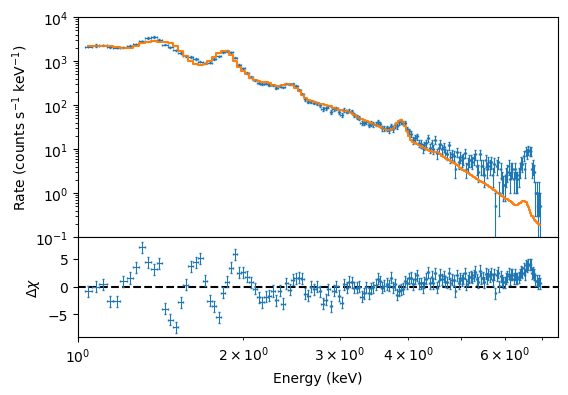

In [10]:
doPlot()

Even with this, spectra is not well fitted with the model. For such flares, it has been shown that isothermal models are not dufficient to explain the observed spectrum, but multithermal models are required (see [Mithun et al 2022](https://doi.org/10.3847/1538-4357/ac98b4) for further details). 

#### Fitting spectrum with two temperature model

So, as the next step, we use the next simplest multi-thermal model, sum of two isothermal models. We allow the T and EM of both component vary independantly, but link the abundances of elements between the two models. We again allow abundances of select elements to vary as in the previous case. 

In [11]:
m1 = Model("chisoth+chisoth")

for p in range(2,31):
    m1(p+31).link=m1(p)

m1(12).frozen=False
m1(14).frozen=False
m1(16).frozen=False
m1(18).frozen=False
m1(20).frozen=False
m1(26).frozen=False

Fit.perform()
Plot('ld','delc')


Model chisoth<1> + chisoth<2> Source No.: 1   Active/On
Model Model Component  Parameter  Unit     Value
 par  comp
   1    1   chisoth    logT       K        6.39000      +/-  0.0          
   2    1   chisoth    He                  10.9000      frozen
   3    1   chisoth    Li                  1.64000      frozen
   4    1   chisoth    Be                  1.94000      frozen
   5    1   chisoth    B                   3.09000      frozen
   6    1   chisoth    C                   8.59000      frozen
   7    1   chisoth    N                   8.00000      frozen
   8    1   chisoth    O                   8.89000      frozen
   9    1   chisoth    F                   4.56000      frozen
  10    1   chisoth    Ne                  8.08000      frozen
  11    1   chisoth    Na                  6.93000      frozen
  12    1   chisoth    Mg                  8.15000      frozen
  13    1   chisoth    Al                  7.04000      frozen
  14    1   chisoth    Si                  8.10000  


Parameters defined:
Model chisoth<1> + chisoth<2> Source No.: 1   Active/On
Model Model Component  Parameter  Unit     Value
 par  comp
   1    1   chisoth    logT       K        7.14701      +/-  7.45421E-03  
  12    1   chisoth    Mg                  8.21805      +/-  3.05656E-02  
  14    1   chisoth    Si                  7.90647      +/-  2.43134E-02  
  16    1   chisoth    S                   7.09349      +/-  3.23967E-02  
  18    1   chisoth    Ar                  6.28063      +/-  0.156429     
  20    1   chisoth    Ca                  7.03560      +/-  5.05098E-02  
  26    1   chisoth    Fe                  8.00812      +/-  2.92899E-02  
  31    1   chisoth    norm                22.8999      +/-  1.49235      
  32    2   chisoth    logT       K        6.77637      +/-  8.79900E-03  
  62    2   chisoth    norm                140.532      +/-  10.4098      
________________________________________________________________________



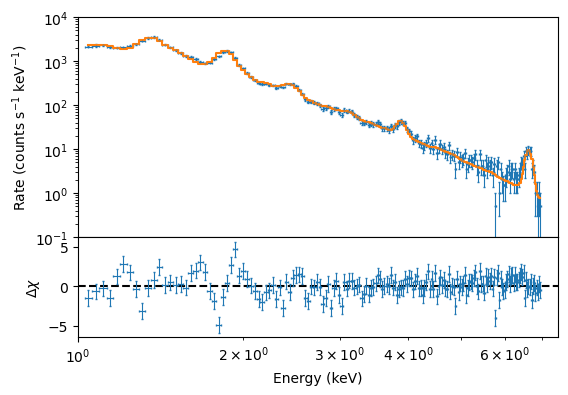

In [12]:
AllModels.show(parIDs="1 12 14 16 18 20 26 31 32 62")
doPlot()

We can see that the spectrum is now well fitted by the model. We can also save the fit details to and xcm file using the commands below. 

In [13]:
# Save the fit details to xcm file 

fxcm=specbase+'_twoTFit.xcm'

# Caution!!: remove previous xcm file
if (os.path.isfile(fxcm)):
    os.remove(fxcm)
    
Xset.save(fxcm)

#### MCMC analysis

We now carry out MCMC analysis on the data to identify the parameter distributions rather than just the best fit parameters.

In [14]:
# Clear previous data/model

AllModels.clear()
AllData.clear()

# Restore the fit details from xcm file (load data, define model with selected free par)
Xset.restore(fxcm)

Fit.perform()

# Store best fit parameters to variable

freepar=[1,12,14,16,18,20,26,31,32,62]
nfreepar=len(freepar)
fitpar=np.zeros(nfreepar)
    
for j in range(0,nfreepar):
    fitpar[j]=AllModels(1)(freepar[j]).values[0]


Default fit statistic is set to: Chi-Squared
   This will apply to all current and newly loaded spectra.

1 spectrum  in use
 
Spectral Data File: ch2_xsm_20210908_172100-172200.pha  Spectrum 1
Net count rate (cts/s) for Spectrum:1  2.412e+03 +/- 1.674e+01
 Assigned to Data Group 1 and Plot Group 1
  Noticed Channels:  1-512
  Telescope: CH-2_ORBITER Instrument: CH2_XSM  Channel Type: PI
  Exposure Time: 59.28 sec
 Using fit statistic: chi
 Using Response (RMF) File            /Users/mithun/work/chandrayaan/xsm/pipeline/XSM/xsmdas/caldb/CH2xsmresponse20200423v01.rmf for Source 1
 Using Auxiliary Response (ARF) File  ch2_xsm_20210908_172100-172200.arf

    16 channels (1,16) ignored in spectrum #     1
   316 channels (197,512) ignored in spectrum #     1

 Solar Abundance Vector set to angr:  Anders E. & Grevesse N. Geochimica et Cosmochimica Acta 53, 197 (1989)
 Cross Section Table set to vern:  Verner, Ferland, Korista, and Yakovlev 1996
Parameter delta values for fits will now be 0.

In [16]:
#Clear existing chains

AllChains -= '*'

# run mcmc chain
chainfile=specbase+'_twoT_chain.fits'

runLength=10000
burn=500

# run again only if previous run output not stored in file
if (not os.path.isfile(chainfile)):
    Chain(chainfile, burn=burn, runLength=runLength, rand=True, algorithm='gw', walkers=8)
else:
    AllChains +=chainfile


   All chains are now removed.
  New chain ch2_xsm_20210908_172100-172200_twoT_chain.fits is now loaded.
  Default chain length is now set to length of ch2_xsm_20210908_172100-172200_twoT_chain.fits: 10000


Plot chain outputs using XSPEC plot commands

In [16]:
Plot('chain 0')

In [17]:
Plot('chain 1')

In [18]:
Plot('chain 12')

In [19]:
Plot('chain 1 31')

Compute errors using MCMC chain

In [17]:
Fit.error("1.0 1 12 14 16 18 20 26 31 32 62")

Errors calculated from chains
 Parameter   Credible Interval (68.27%)
     1      7.13955      7.15273    (-0.00745741,0.00572384)
    12      8.20112      8.25062    (-0.0169333,0.032575)
    14      7.89801      7.92769    (-0.00846077,0.0212215)
    16      7.06669      7.12885    (-0.0268048,0.0353602)
    18      5.97492      6.31694    (-0.30571,0.0363135)
    20      6.97113      7.07815    (-0.0644702,0.0425541)
    26      7.99656      8.03235    (-0.0115588,0.024232)
    31      21.5891       24.313    (-1.31031,1.41363)
    32      6.76786      6.78362    (-0.00851294,0.00725443)
    62      130.082      146.812    (-10.447,6.28276)


Use corner.py  to get corner plots of MCMC result

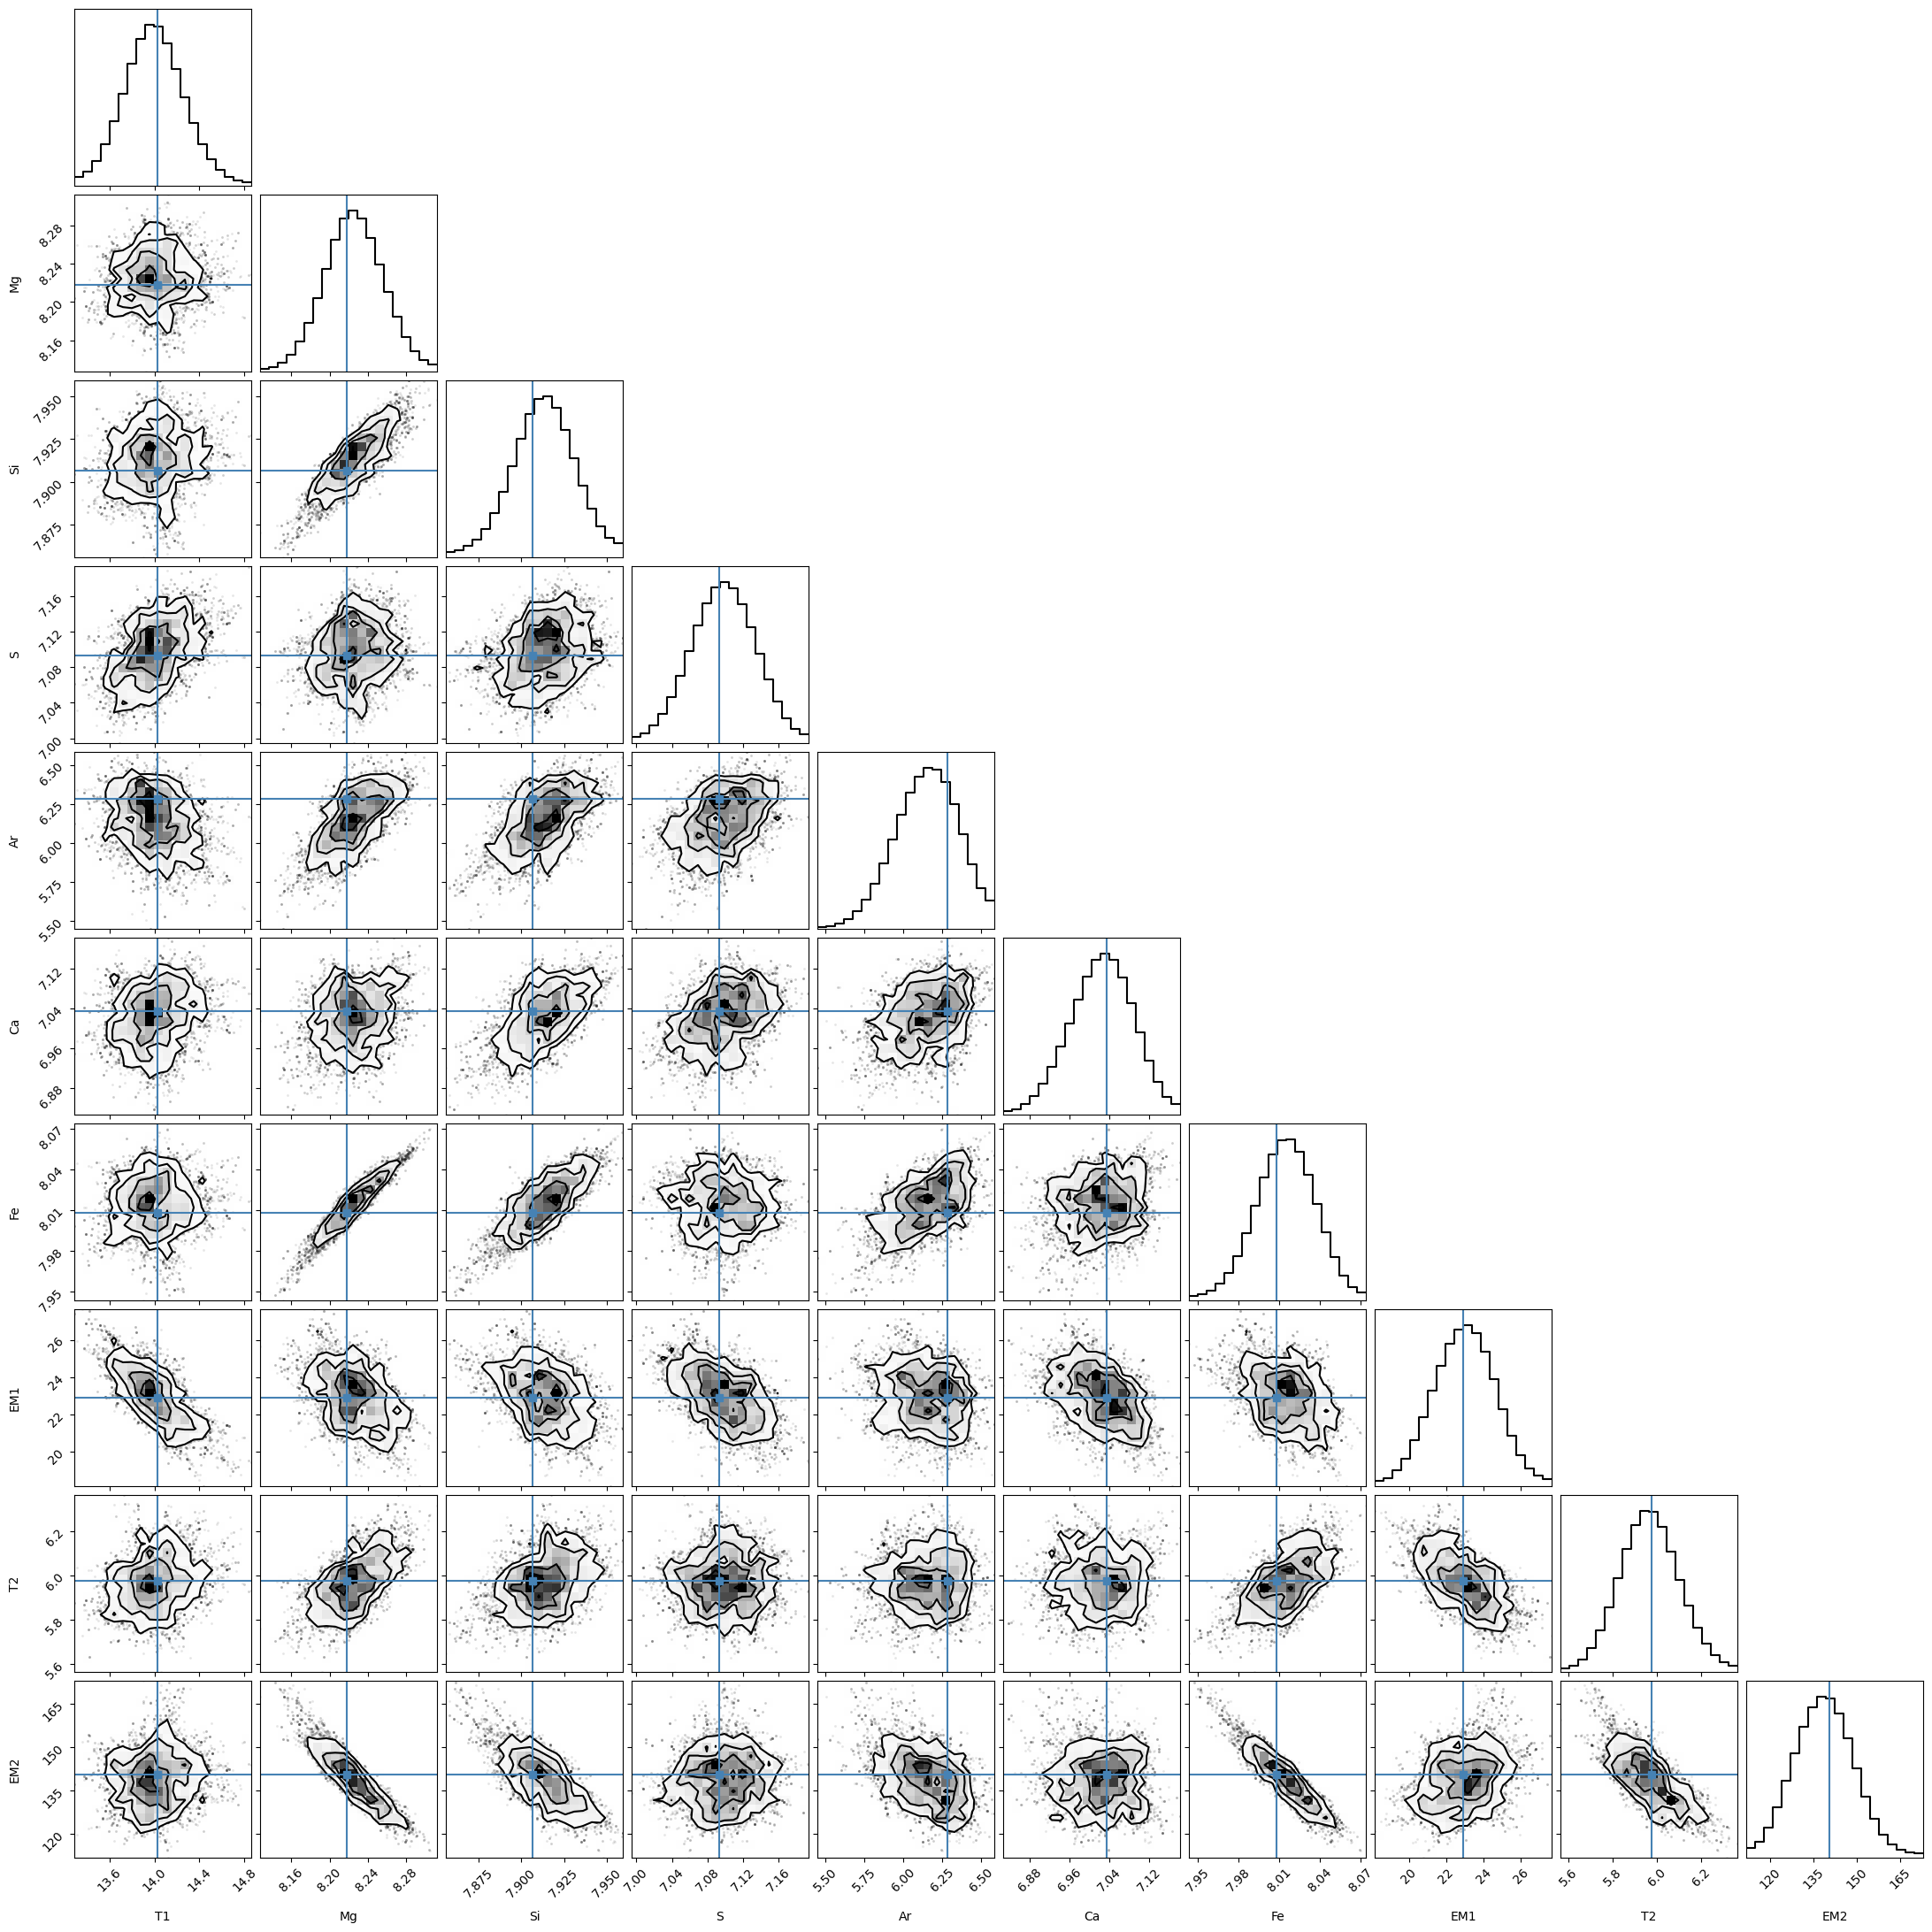

In [18]:
fhdu = fits.open(chainfile)
fdata = fhdu[1].data
fdata

T1=fdata['LogT__1']
EM1=fdata['norm__31']

T2=fdata['LogT__32']
EM2=fdata['norm__62']

allpar=[10**(T1-6.0),fdata['Mg__12'],fdata['Si__14'],fdata['S__16'],fdata['Ar__18'],fdata['Ca__20'],fdata['Fe__26'],EM1,10**(T2-6.0),EM2]
pbest=np.array(fitpar)
pbest[0]=10**(pbest[0]-6.0)
pbest[-2]=10**(pbest[-2]-6.0)

params=['T1','Mg','Si','S','Ar','Ca','Fe','EM1','T2','EM2']

fig1=corner.corner(np.transpose(allpar),truths=pbest,smooth1d=2,labels=params,bins=20)
plt.show()
plt.close()

